# 02 - Preprocessing: from waveforms to spectrograms and scalograms

For every record:
1. the mean of the recorded samples is removed from each component (zero padding stays zero);
2. the analysis window is placed around the peak absolute acceleration over the three components (PGA),
   from `pre_pga_s` before to `post_pga_s` after; the same window is used for the three components;
3. the window, extended by a context margin on both sides, is tapered, low-pass filtered and resampled;
4. spectrogram (STFT) and scalogram (Morlet CWT) are computed on the extended window and cropped to the window,
   on a common grid of logarithmic frequencies and time bins;
5. the power is converted to absolute decibels and stored as arrays of shape (components, frequencies, times).

Every parameter is read from the `preprocessing` section of `configs/default.yaml`.
The records come from `waveforms.source` (development subset now, full dataset later).

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wqu.config import load_config
from wqu.data.exploration import numeric_summary_by_label
from wqu.data.inspection import share_by_label
from wqu.data.loading import CV_COMPONENTS, load_esm25_metadata
from wqu.data.sampling import sample_records_per_label
from wqu.data.waveforms import (
    iter_waveform_batches,
    load_waveforms,
    select_inspection_records,
    stored_sampling_rate_hz,
)
from wqu.preprocessing.pipeline import (
    FEATURE_INDEX_COLUMN,
    REPRESENTATIONS,
    feature_file_path,
    grid_from_config,
    pooled_power_values,
    preprocess_and_store,
    process_record,
    read_features,
    window_table,
)
from wqu.preprocessing.transform import power_to_db
from wqu.visualization import (
    apply_plot_style,
    plot_representation_comparison,
    plot_value_distributions,
    plot_window_overlay,
    save_figure,
)

CONFIG_PATH = Path("..") / "configs" / "default.yaml"

config = load_config(CONFIG_PATH)
apply_plot_style()
columns = config.columns
preprocessing = config.preprocessing
tolerance = config.waveforms.zero_tolerance
label_names = {subset.label: subset.name for subset in config.data.subsets}
for directory in (preprocessing.figures_dir, preprocessing.tables_dir, preprocessing.figures_dir / "png_checks"):
    directory.mkdir(parents=True, exist_ok=True)

grid = grid_from_config(preprocessing)
print(f"Window: {preprocessing.pre_pga_s:g} s before to {preprocessing.post_pga_s:g} s after the PGA "
      f"(+ {preprocessing.context_margin_s:g} s margin on each side)")
print(f"Resampling: {preprocessing.target_sampling_rate_hz:g} Hz after a low-pass at {preprocessing.antialias_corner_hz:g} Hz")
print(f"Grid: {preprocessing.n_frequencies} frequencies from {preprocessing.min_frequency_hz:g} to "
      f"{preprocessing.max_frequency_hz:g} Hz (log), {preprocessing.n_times} time bins of "
      f"{preprocessing.window_length_s / preprocessing.n_times:.3f} s")
print(f"STFT window: {preprocessing.stft_window_s:g} s ({preprocessing.stft_window_type}); "
      f"Morlet w0 = {preprocessing.morlet_w0:g}")

Window: 30 s before to 90 s after the PGA (+ 20 s margin on each side)
Resampling: 100 Hz after a low-pass at 40 Hz
Grid: 128 frequencies from 0.1 to 40 Hz (log), 128 time bins of 0.938 s
STFT window: 10 s (hann); Morlet w0 = 6


/Users/giulianaparadiso/miniconda3/envs/wqu/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
_, metadata = load_esm25_metadata(config)
records = select_inspection_records(metadata, config)
sampling_rate_hz = stored_sampling_rate_hz(metadata)
print(f"Waveform source: {config.waveforms.source}; records: {len(records):,}")
records[columns.label].value_counts().rename(index=label_names)

Waveform source: dev_subset; records: 2,000


label
good    1000
bad     1000
Name: count, dtype: int64

## 1. Analysis window: what is kept and what is cut

For every record:
- `pga_time_s`: time of the PGA from the start of the stored trace;
- `nonzero_cut_before_c`, `nonzero_cut_after_c`: recorded (non-zero) samples of component c removed before and after the window;
- `missing_in_window_s_c`: seconds of the window without data on component c (window reaching beyond the recording);
- `recorded_fraction_kept`, `energy_fraction_kept`: share of the recorded samples and of the signal energy (sum of squared amplitudes) inside the window.

In [3]:
windows = window_table(iter_waveform_batches(records, config), sampling_rate_hz, preprocessing, tolerance)
windows = records[[columns.label, "trace_name_old", columns.station_id]].join(windows)
for side in ("before", "after"):
    windows[f"cut_{side}_s"] = windows[[f"nonzero_cut_{side}_{c}" for c in CV_COMPONENTS]].max(axis=1) / sampling_rate_hz
windows["missing_in_window_s"] = windows[[f"missing_in_window_s_{c}" for c in CV_COMPONENTS]].max(axis=1)
windows.to_csv(preprocessing.tables_dir / f"window_statistics_{config.waveforms.source}.csv")

WINDOW_COLUMNS = ["pga_time_s", "cut_before_s", "cut_after_s", "missing_in_window_s", "recorded_fraction_kept", "energy_fraction_kept"]
numeric_summary_by_label(windows, WINDOW_COLUMNS, columns.label).rename(index=label_names, level=columns.label).round(3)

count     mean     std    min     25%      50%  \
column                 label                                                    
pga_time_s             good   1000.0   80.762  42.389  0.180  69.230   82.590   
                       bad    1000.0  112.532  75.826  0.000  73.628   91.580   
cut_before_s           good   1000.0   52.933  39.115  0.000  39.230   52.590   
                       bad    1000.0   84.211  73.697  0.000  43.628   61.580   
cut_after_s            good   1000.0   96.402  60.099  0.000  61.838  107.098   
                       bad    1000.0   90.732  69.471  0.000   8.105  103.765   
missing_in_window_s    good   1000.0   11.312  24.906  0.000   0.000    0.000   
                       bad    1000.0   14.239  27.687  0.000   0.000    0.000   
recorded_fraction_kept good   1000.0    0.510   0.228  0.080   0.386    0.428   
                       bad    1000.0    0.422   0.177  0.000   0.328    0.410   
energy_fraction_kept   good   1000.0    0.913   0.166  0.028   0.912    0.988   
                       bad    1000.0    0.615   0.261  0.000   0.412    0.606   

                                  75%      max  
column                 label                    
pga_time_s             good    97.639  365.650  
                       bad    131.345  388.840  
cut_before_s           good    67.639  335.650  
                       bad    101.345  358.840  
cut_after_s            good   128.071  267.885  
                       bad    135.984  291.205  
missing_in_window_s    good     0.000  113.035  
                       bad     13.252  120.000  
recorded_fraction_kept good     0.466    1.000  
                       bad      0.434    1.000  
energy_fraction_kept   good     0.999    1.000  
                       bad      0.860    1.000

In [4]:
window_flags = pd.DataFrame(
    {
        "window starts before the recording": windows["window_start"] < 0,
        "window ends after the stored trace": windows["window_stop"] > config.data.waveform_length_s * sampling_rate_hz,
        "some data missing in the window": windows["missing_in_window_s"] > 0,
        "energy kept < 95%": windows["energy_fraction_kept"] < 0.95,
        "energy kept < 80%": windows["energy_fraction_kept"] < 0.80,
    }
)
share_by_label(window_flags, windows[columns.label]).rename(columns=label_names).round(3)

label,good,bad
window starts before the recording,0.144,0.103
window ends after the stored trace,0.001,0.014
some data missing in the window,0.228,0.316
energy kept < 95%,0.330,0.854
energy kept < 80%,0.131,0.686


## 2. Visual check of the cut

The full stored trace in light grey and the analysis window in dark grey (shaded):
random records of each class, then the records that keep the smallest share of their energy.

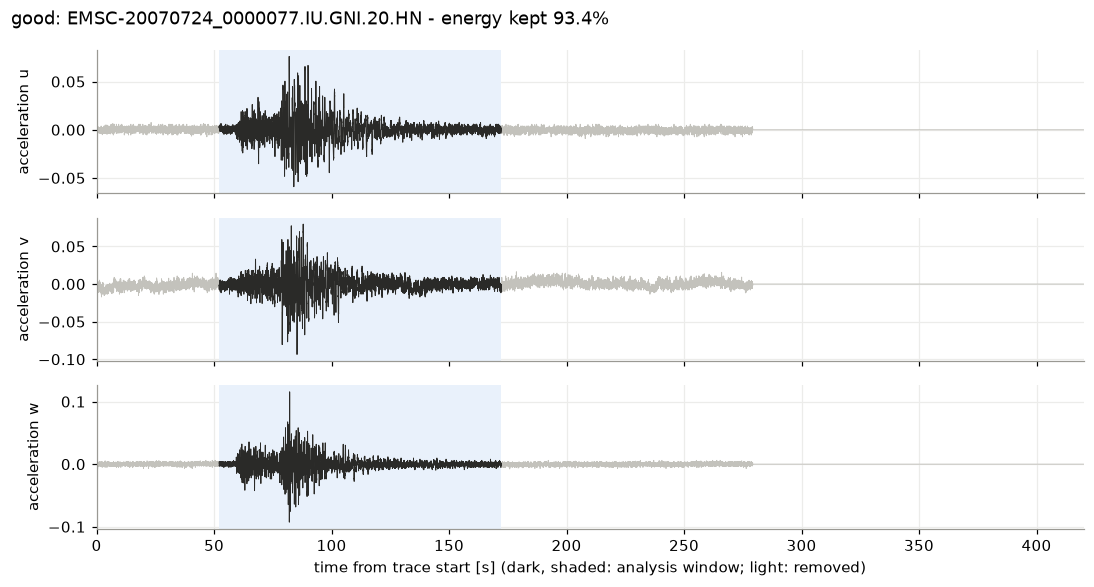

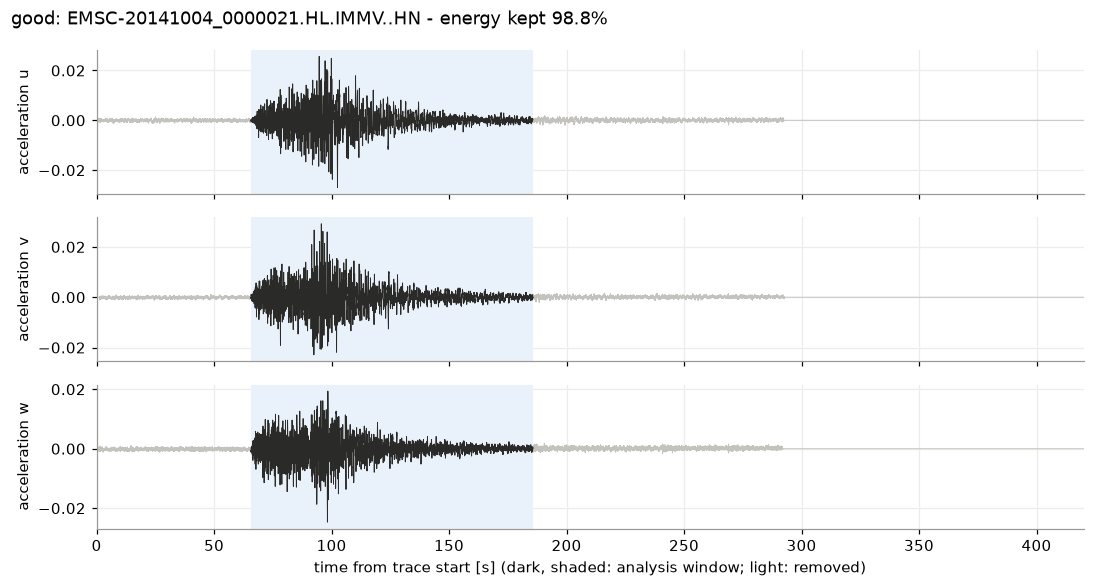

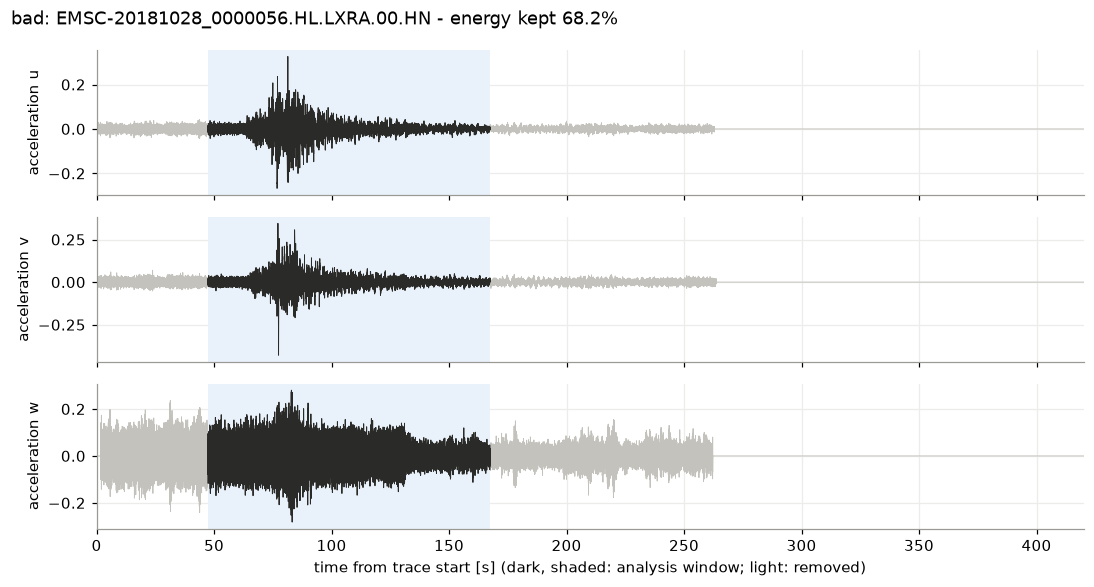

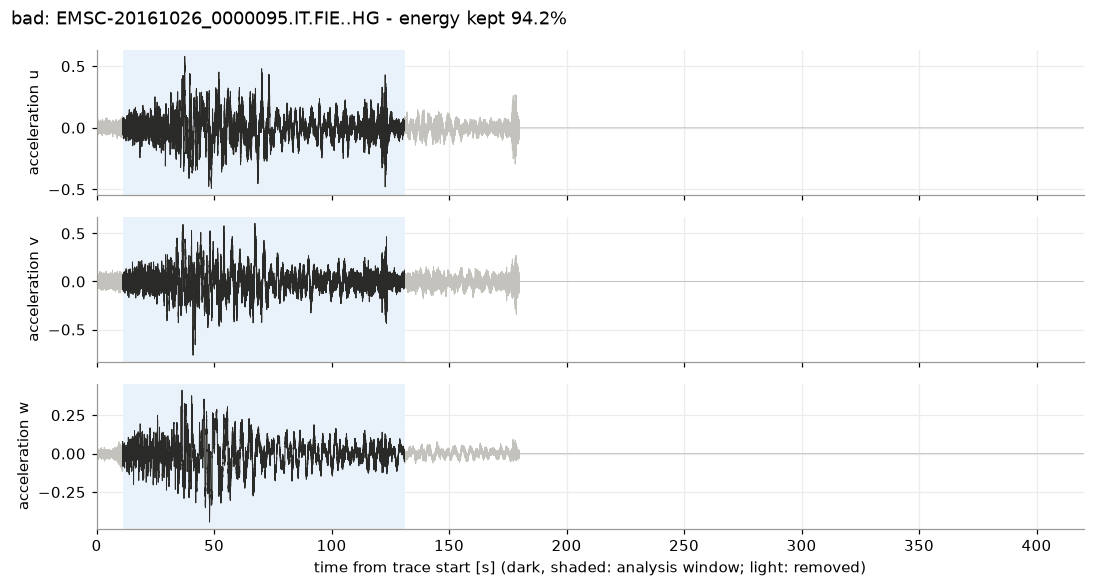

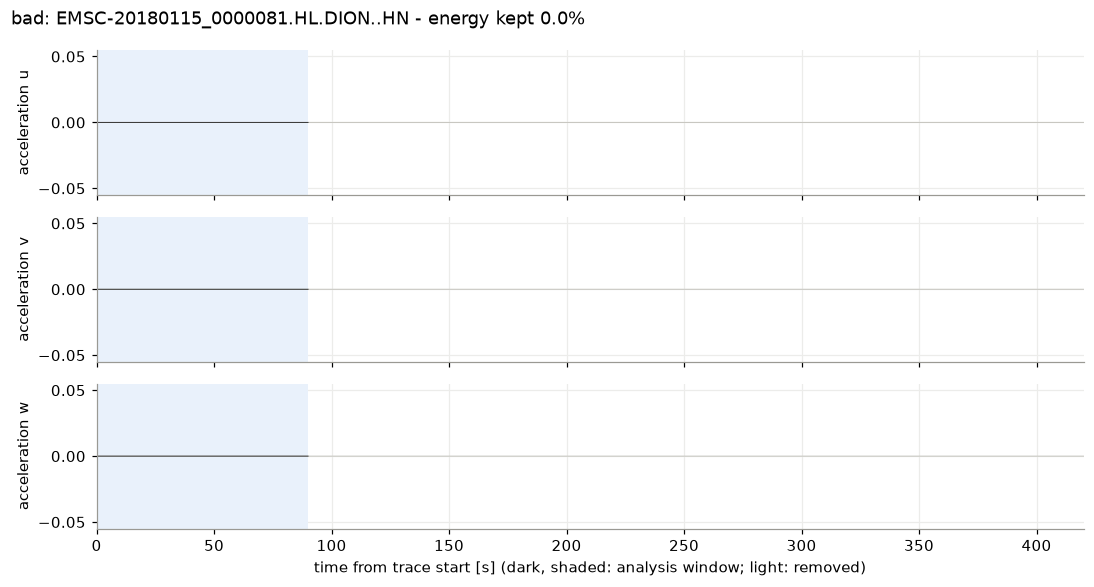

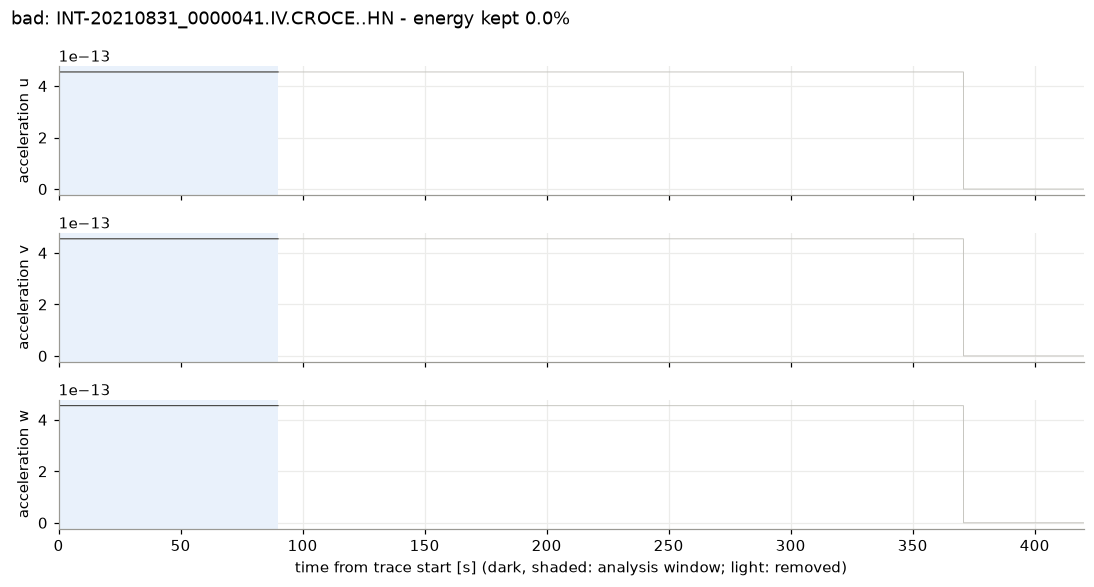

In [5]:
N_RANDOM_EXAMPLES = 2
N_LOWEST_ENERGY_EXAMPLES = 2

random_examples = windows.groupby(columns.label, group_keys=False).sample(
    n=N_RANDOM_EXAMPLES, random_state=config.waveforms.random_seed
)
lowest_energy = windows.nsmallest(N_LOWEST_ENERGY_EXAMPLES, "energy_fraction_kept")
examples = pd.concat([random_examples, lowest_energy])
example_traces = load_waveforms(records.loc[examples.index], config)

for (index, window), trace in zip(examples.iterrows(), example_traces):
    title = (f"{label_names[window[columns.label]]}: {window['trace_name_old']} - "
             f"energy kept {window['energy_fraction_kept']:.1%}")
    figure = plot_window_overlay(trace, sampling_rate_hz, int(window["window_start"]), int(window["window_stop"]),
                                 CV_COMPONENTS, title)
    save_figure(figure, preprocessing.figures_dir / f"window_{window['trace_name_old']}.png")
    plt.show()

## 3. Spectrogram and scalogram of one record

Comparison figure for a record of the station with most records in the inspected set
(waveform of the window, spectrogram and scalogram; one row per component).

{'spectrogram': (3, 128, 128), 'scalogram': (3, 128, 128)}


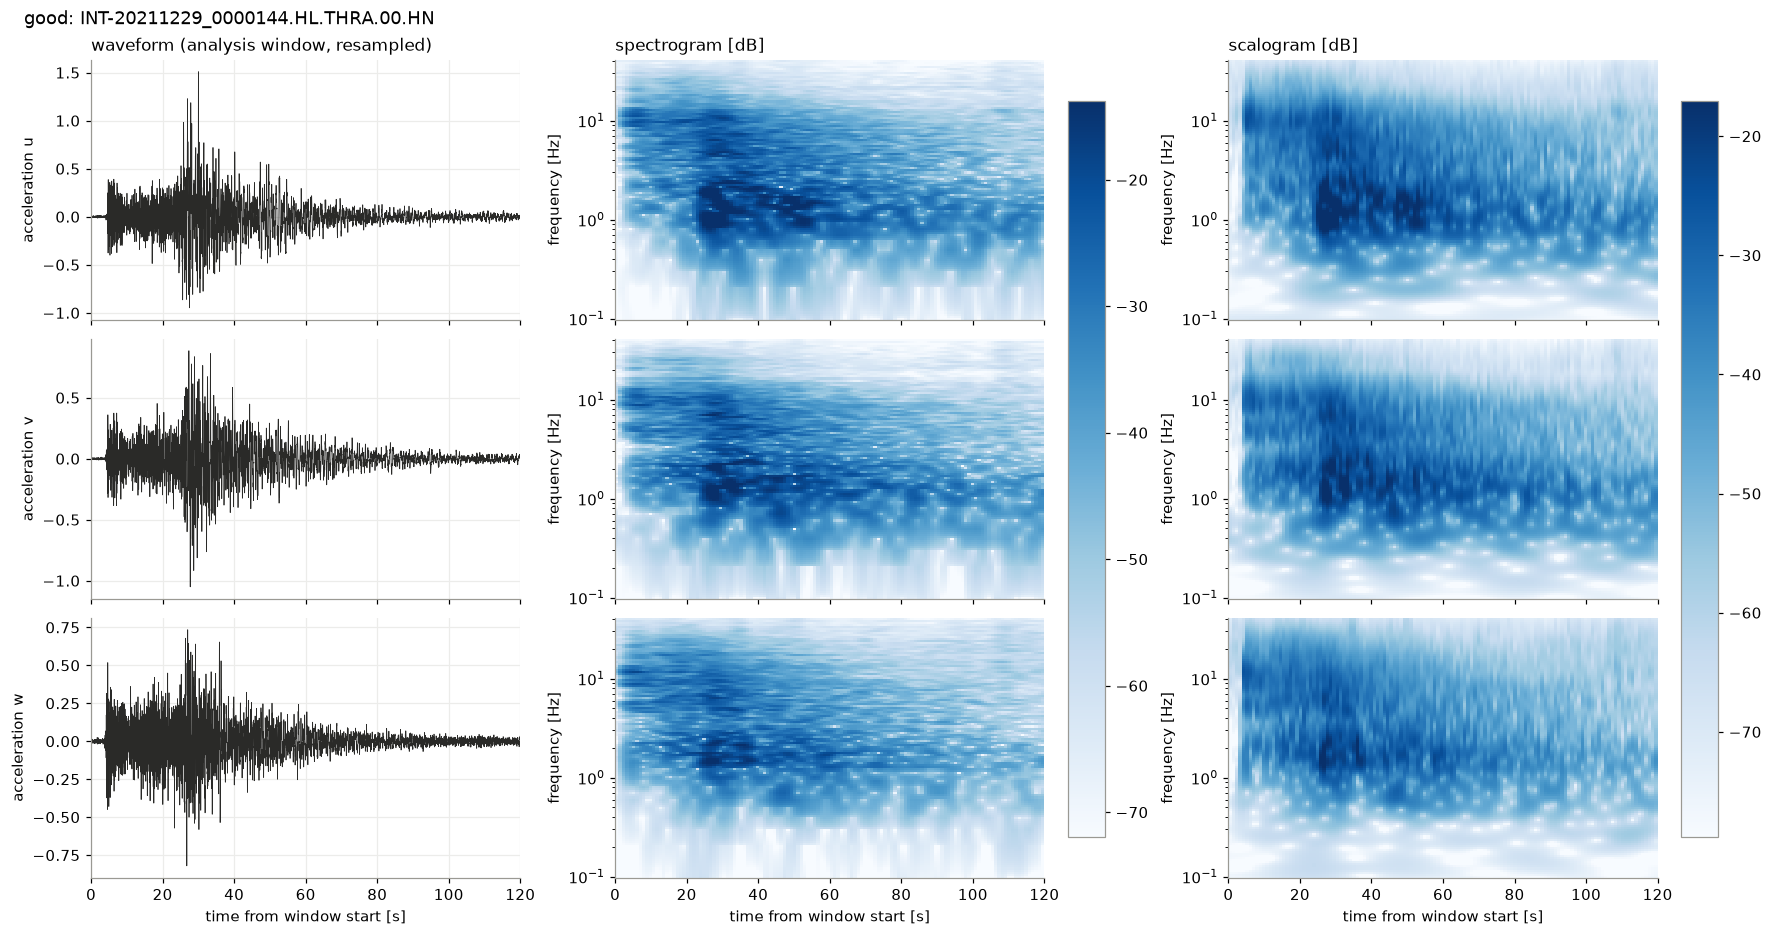

In [6]:
example_station = records[columns.station_id].value_counts().index[0]
station_record = records[records[columns.station_id] == example_station].iloc[[0]]
station_trace = load_waveforms(station_record, config)[0]
processed = process_record(station_trace, sampling_rate_hz, preprocessing, grid, tolerance)
station_db = {name: power_to_db(processed.power[name], preprocessing.reference_power, preprocessing.floor_power)
              for name in REPRESENTATIONS}

record_name = station_record["trace_name_old"].iloc[0]
figure = plot_representation_comparison(
    processed.window_waveform, preprocessing.target_sampling_rate_hz,
    station_db["spectrogram"], station_db["scalogram"],
    grid.frequency_edges_hz, grid.times_s, CV_COMPONENTS,
    f"{label_names[station_record[columns.label].iloc[0]]}: {record_name}",
)
save_figure(figure, preprocessing.figures_dir / f"comparison_{example_station}.png")
print({name: values.shape for name, values in station_db.items()})

## 4. Power distributions and decibel floor

Power values of a sample of records, pooled over components, frequencies and times.
Zeros (components without data, windows reaching beyond the recording) cannot be converted to decibels:
they are raised to `decibel.floor_power`. The floor should lie below the weakest real values (instrument noise),
so that it marks missing data without clipping real signal. Update `floor_power` in the configuration if needed.

In [7]:
distribution_records = sample_records_per_label(
    records,
    label_column=columns.label,
    group_column=columns.event_id,
    records_per_label=preprocessing.n_distribution_records // 2,
    max_records_per_group=None,
    seed=config.waveforms.random_seed,
)
pooled = pooled_power_values(
    iter_waveform_batches(distribution_records, config), sampling_rate_hz, preprocessing, tolerance
)
QUANTILES = [0.0, 0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 1.0]
summary = pd.DataFrame({name: np.quantile(values, QUANTILES) for name, values in pooled.items()}, index=QUANTILES)
summary.index.name = "quantile"
for name, values in pooled.items():
    print(f"{name}: zeros {np.mean(values == 0):.4%}, below the current floor "
          f"({preprocessing.floor_power:g}) {np.mean(values < preprocessing.floor_power):.4%}")
summary

spectrogram: zeros 7.4247%, below the current floor (1e-12) 9.1450%
scalogram: zeros 0.0000%, below the current floor (1e-12) 8.9219%


,spectrogram,scalogram
quantile,,
0.000,0.000000e+00,1.309861e-24
0.001,0.000000e+00,2.257975e-23
0.010,0.000000e+00,5.641187e-22
0.050,0.000000e+00,2.742207e-18
0.500,3.842173e-07,1.662269e-07
0.950,8.075179e-04,3.965433e-04
0.990,4.188792e-02,2.186938e-02
1.000,3.394525e+02,1.199821e+02


PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/outputs/figures/02_preprocessing/power_distributions_dev_subset.png')

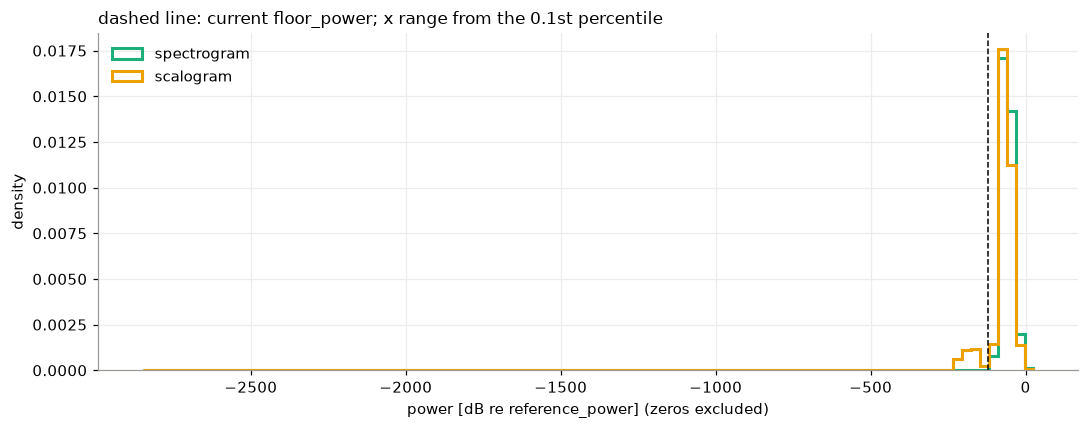

In [8]:
figure, ax = plt.subplots(figsize=(10, 4))
positive_db = {name: 10.0 * np.log10(values[values > 0] / preprocessing.reference_power) for name, values in pooled.items()}
plot_value_distributions(positive_db, ax, "power [dB re reference_power] (zeros excluded)", quantile_range=(0.001, 1.0))
ax.axvline(10.0 * np.log10(preprocessing.floor_power / preprocessing.reference_power), color="black", linewidth=1.0,
           linestyle="--")
ax.set_title("dashed line: current floor_power; x range from the 0.1st percentile", loc="left")
figure.tight_layout()
save_figure(figure, preprocessing.figures_dir / f"power_distributions_{config.waveforms.source}.png")

## 5. Compute and store all records

One HDF5 file per waveform source in `preprocessing.output_dir`, with the decibel arrays of both representations
(float16, not yet standardized: the standardization statistics will be computed on the training set only),
the grid and the preprocessing parameters; `records.csv` next to it links each row (`feature_index`) to its record.

In [9]:
features_path = feature_file_path(preprocessing, config.waveforms.source)
stored_records = preprocess_and_store(
    records, iter_waveform_batches(records, config), sampling_rate_hz, preprocessing, tolerance, features_path
)
print(f"Stored {len(stored_records):,} records in {features_path}")

preprocessing: 100%|██████████| 2000/2000 [02:16<00:00, 14.70it/s]


Stored 2,000 records in /Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/data/processed/dev_subset/features.h5


## 6. PNG images for visual inspection

Comparison figures read back from the stored arrays (spectrogram and scalogram) for a few records of each class,
saved in `figures_dir/png_checks/`. These images are for inspection only; the networks use the stored arrays.

In [10]:
png_records = stored_records.groupby(columns.label, group_keys=False).sample(
    n=preprocessing.n_png_records_per_class, random_state=config.waveforms.random_seed
)
rows = png_records[FEATURE_INDEX_COLUMN].to_numpy()
stored_db = {name: read_features(features_path, name, rows)[0] for name in REPRESENTATIONS}
png_traces = load_waveforms(records.loc[png_records.index], config)

for position, ((index, record), trace) in enumerate(zip(png_records.iterrows(), png_traces)):
    window_waveform = process_record(trace, sampling_rate_hz, preprocessing, grid, tolerance).window_waveform
    figure = plot_representation_comparison(
        window_waveform, preprocessing.target_sampling_rate_hz,
        stored_db["spectrogram"][position], stored_db["scalogram"][position],
        grid.frequency_edges_hz, grid.times_s, CV_COMPONENTS,
        f"{label_names[record[columns.label]]}: {record['trace_name_old']}",
    )
    save_figure(figure, preprocessing.figures_dir / "png_checks" / f"{label_names[record[columns.label]]}_{record['trace_name_old']}.png")
    plt.close(figure)
print(f"Saved {len(png_records)} PNG images in {preprocessing.figures_dir / 'png_checks'}")

Saved 10 PNG images in /Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/outputs/figures/02_preprocessing/png_checks
